# Task 1 — Random Forest Classifier (Churn Prediction)

Codveda ML Internship — Alen Gevorgyan (CV/AI/82079)

Using the "Churn Prediction Data" set from the shared drive. Goal here is to build a Random Forest that can flag customers likely to churn, tune it properly instead of just eyeballing defaults, and see which features actually drive the prediction.

Rough plan:
1. Load + take a look at the raw data
2. Quick EDA (class balance, correlations)
3. Preprocess (handled mostly in `data_loader.py` so this notebook doesn't turn into a wall of pandas)
4. Grid search over `n_estimators` / `max_depth`
5. Evaluate with precision/recall/f1 + cross-val
6. Feature importance

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from data_loader import load_raw_data, get_processed_data, RAW_DATA_PATH

sns.set_style("whitegrid")
%matplotlib inline

## 1. Raw data peek

Just want to see what I'm actually working with before doing anything to it.

In [2]:
raw_df = load_raw_data(RAW_DATA_PATH)
print(raw_df.shape)
raw_df.head()

(2666, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   float64
 15

In [4]:
raw_df.isna().sum().sort_values(ascending=False).head(10)

State                    0
Account length           0
Area code                0
International plan       0
Voice mail plan          0
Number vmail messages    0
Total day minutes        0
Total day calls          0
Total day charge         0
Total eve minutes        0
dtype: int64

## 2. Quick EDA

Mainly want to check: (a) is the target imbalanced, and (b) do any features obviously correlate with churn.

using: Churn


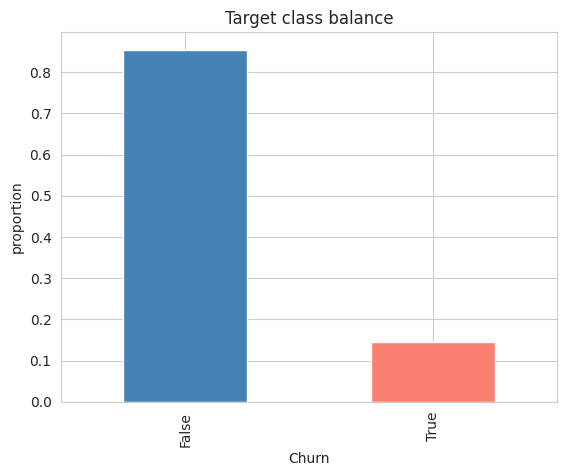

In [5]:
target_guess = [c for c in raw_df.columns if "churn" in c.lower()]
target_guess = target_guess[0] if target_guess else raw_df.columns[-1]
print("using:", target_guess)

raw_df[target_guess].value_counts(normalize=True).plot(kind="bar", color=["steelblue", "salmon"])
plt.title("Target class balance")
plt.ylabel("proportion")
plt.show()

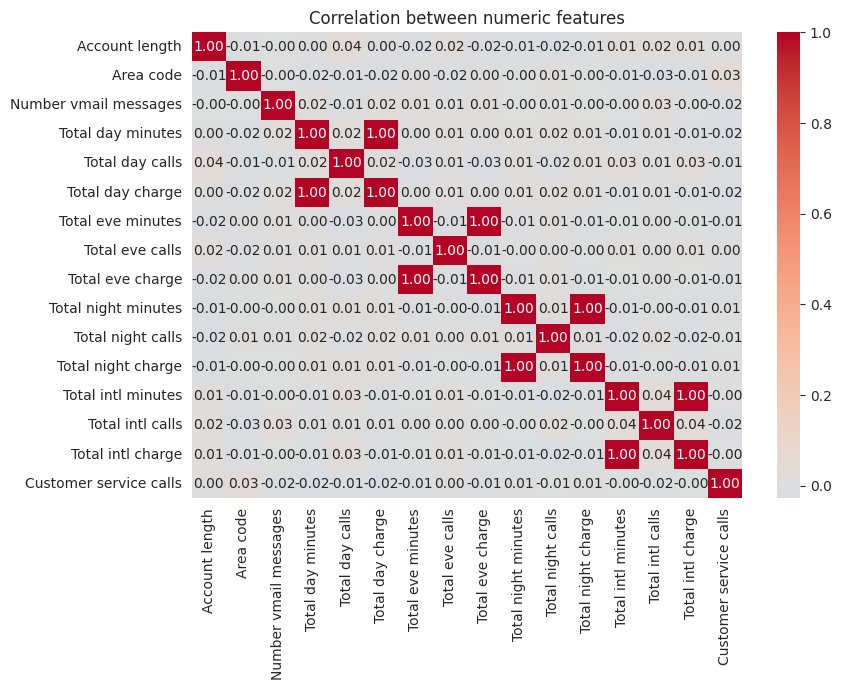

In [6]:
numeric_cols = raw_df.select_dtypes(include=[np.number]).columns
if len(numeric_cols) > 1:
    plt.figure(figsize=(9, 7))
    sns.heatmap(raw_df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation between numeric features")
    plt.tight_layout()
    plt.show()
else:
    print("not enough numeric cols for a correlation heatmap pre-encoding, skipping")

~85% no-churn / ~15% churn (388 churners out of 2666 customers). Skewed, which is pretty normal for churn data, but not so skewed that it's unworkable. Kept `stratify=y` in the train/test split in `data_loader.py` so both sets keep the same ratio -- otherwise the smaller test set especially could end up with barely any churn examples in it. Also worth keeping in mind for evaluation: with this kind of imbalance, overall accuracy alone would be a pretty misleading metric (a model that just predicts "no churn" every time would still score ~85% accuracy), which is exactly why precision/recall/F1 on the churn class specifically matter more here.

## 3. Preprocess + train/test split

All the cleanup (dropping ID cols, encoding, scaling) lives in `data_loader.py`.

In [7]:
data = get_processed_data()
print("train:", data["X_train"].shape, " test:", data["X_test"].shape)
print("num features after encoding:", len(data["feature_names"]))

[data_loader] loaded 2666 rows, 20 columns
[data_loader] target classes: [np.False_, np.True_]
train: (2132, 68)  test: (534, 68)
num features after encoding: 68


## 4. Hyperparameter tuning

Grid searching `n_estimators`, `max_depth`, `min_samples_split` with 5-fold CV, scoring on weighted F1 since the classes aren't perfectly balanced.

In [8]:
from train_rf import tune_model, PARAM_GRID

print("grid:", PARAM_GRID)
best_model, best_params = tune_model(data["X_train"], data["y_train"])

grid: {'n_estimators': [100, 200, 400], 'max_depth': [None, 5, 10, 20], 'min_samples_split': [2, 5]}
Fitting 5 folds for each of 24 candidates, totalling 120 fits



best params found: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 400}
best CV f1 (weighted): 0.9287


Best combo came out to `n_estimators=400`, `max_depth=None`, `min_samples_split=5` (weighted CV F1 ~0.929). `max_depth=None` winning over the capped values makes sense here, letting the trees grow out fully picks up more signal, and `min_samples_split=5` (instead of the default 2) is doing enough regularizing on its own to keep that from turning into overfitting -- the 5-fold CV scores below stay tight together (std ~0.006), which is what I'd want to see before trusting the tuned model.

## 5. Evaluation

In [9]:
from train_rf import evaluate_model

metrics = evaluate_model(best_model, data["X_train"], data["y_train"], data["X_test"], data["y_test"])
metrics


--- test set performance ---
accuracy : 0.9382
precision: 0.9424
recall   : 0.9382
f1 score : 0.9310

full classification report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.97       456
           1       1.00      0.58      0.73        78

    accuracy                           0.94       534
   macro avg       0.97      0.79      0.85       534
weighted avg       0.94      0.94      0.93       534



5-fold CV f1 (refit model): [0.9357 0.9186 0.9304 0.9319 0.9267]
mean: 0.9287 std: 0.0058
saved confusion matrix -> ../outputs/confusion_matrix.png


{'accuracy': 0.9382022471910112,
 'precision': 0.9423726476873233,
 'recall': 0.9382022471910112,
 'f1': 0.9309913131234041}

## 6. Feature importance

Curious what's actually driving the churn prediction here.

In [10]:
from train_rf import plot_feature_importance

imp_df = plot_feature_importance(best_model, data["feature_names"])
imp_df.head(10)

saved feature importance chart -> ../outputs/feature_importance.png


,feature,importance
5,Total day charge,0.131764
3,Total day minutes,0.123295
15,Customer service calls,0.113317
66,International plan_Yes,0.085949
8,Total eve charge,0.052789
6,Total eve minutes,0.051891
14,Total intl charge,0.042353
13,Total intl calls,0.039937
12,Total intl minutes,0.039445
9,Total night minutes,0.034253
